<a href="https://colab.research.google.com/github/JonathanMtz1103987/Simulaci-n-estocastica/blob/main/Tarea_2_MCMC_Ventas_diarias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea 2. Modelación y simulación de procesos estocásticos

## Modelación y simulación de las ventas diarias de una refaccionaria mediante MCMC

**Universidad Juárez del Estado de Durango**  
Facultad de Ciencias Exactas · Maestría en Estadística Aplicada

# Ventas diarias de la Refaccionaria La Estrella

*Modelación y simulación mediante cadenas de Markov y el algoritmo de Metropolis–Hastings*

Mediana de las ventas netas por día de la semana
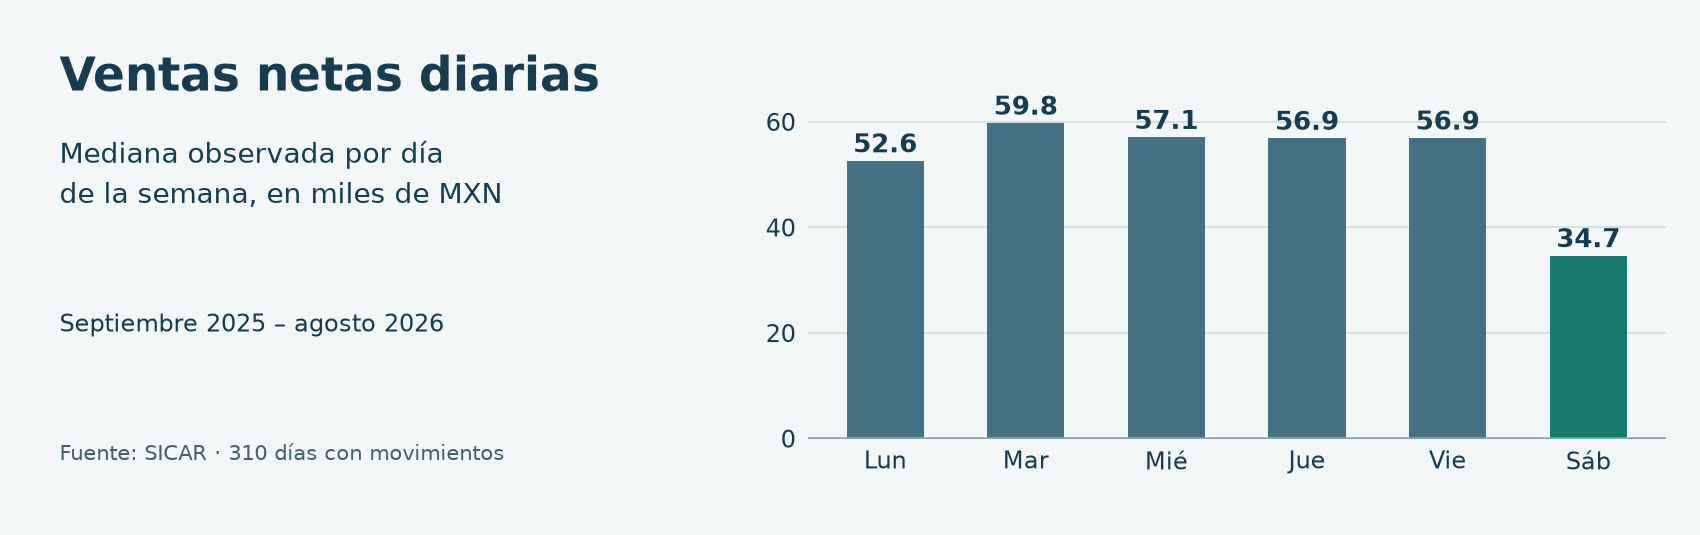

**¿Cuál es la venta neta esperada en un día con movimientos y qué tan probable es que supere los 50,000 MXN?**

---

**Asignatura:** Simulación Estocástica  
**Actividad:** Tarea 2. Modelación y simulación de procesos estocásticos  
**Estudiante:** Jonathan Martínez Pérez  
**Docente:** Dr. Gerónimo Quiñónez-Barraza  
**Fecha de entrega indicada en la actividad:** 15 de noviembre de 2026


Se estudian las ventas netas diarias en pesos mexicanos de la Refaccionaria La Estrella (Refaccionaria con la que previamente se ha estado trabajando en otro modulo del programa de la MAEA). El periodo de ajuste comprende del 1 de septiembre de 2025 al 31 de agosto de 2026. Las observaciones posteriores de septiembre se reservan para evaluar la predicción.

## 1. Librerías

| Librería | Uso en el procedimiento |
|---|---|
| NumPy | Generación pseudoaleatoria, matrices de diseño y almacenamiento de cadenas. |
| pandas | Carga y validación del CSV y presentación de tablas. |
| SciPy | Densidad y acumulada de Student, log-Gamma y optimización de la posterior para configurar la propuesta. |
| Matplotlib | Gráficas de datos, autocorrelación, posteriores y predicción. |
| ArviZ | R-hat por rangos, ESS central y de colas, MCSE y ACF. |
| IPython | Texto y tablas en el notebook, selección del CSV y registro del entorno. |

 La semilla maestra es 42.

In [38]:
import hashlib
from importlib.util import find_spec
from pathlib import Path
import subprocess
import sys
import warnings
if find_spec("arviz") is None:subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "arviz==0.23.4"])
with warnings.catch_warnings(): warnings.filterwarnings("ignore", message=r"\s*ArviZ is undergoing a major refactor",
                            category=FutureWarning, module="arviz")
import arviz as az
from IPython.display import Markdown, display
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import scipy
from scipy.optimize import minimize
from scipy.special import gammaln
from scipy.stats import norm, skew, t as student_t

SEMILLA = 42
sem_piloto, sem_arranque, sem_cadenas, sem_pred = np.random.SeedSequence(SEMILLA).spawn(4)
mpl.rcParams.update({"figure.dpi": 130, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#E1E8EE", "text.color": "#20364A", "axes.labelcolor": "#20364A",})

print(f"Python {sys.version.split()[0]} | semilla maestra {SEMILLA}")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | SciPy {scipy.__version__}")
print(f"Matplotlib {mpl.__version__} | ArviZ {az.__version__}")

Python 3.13.18 | semilla maestra 42
NumPy 2.4.6 | pandas 2.2.3 | SciPy 1.16.3
Matplotlib 3.10.0 | ArviZ 0.22.0


## 2. Variables de estudio

La variación de las ventas diarias afecta la disponibilidad de efectivo y la planeación de inventarios de una refaccionaria. Los totales pueden cambiar con el día de la semana y con la época del año. También pueden registrar saldos negativos cuando los movimientos de ajuste o devolución superan las ventas del día.

| Elemento | Definición |
|---|---|
| Variable principal $V_i$ | Suma de los importes netos de los movimientos del día $i$, en MXN. |
| Unidad de análisis | Un día con al menos un movimiento registrado. |
| Naturaleza y dominio | Cuantitativa continua, con valores monetarios redondeados a centavos y soporte modelado en $\mathbb R$ (Ya que la base original se habia trabajado en el entorno de R studio). |
| Distribución propuesta | Student con 5 grados de libertad, media dependiente de la fecha y dos escalas para lunes–viernes y sábados. |
| Cantidades a estimar | Venta media esperada en el periodo de ajuste, medias por día de semana, escalas de variación y probabilidad de superar 50,000 MXN. |
| Predicción | Distribución de una venta diaria comparable y predicciones para las fechas posteriores reservadas. |

El umbral de 50,000 MXN es ilustrativo, elegido para expresar una probabilidad. Los resultados se refieren a días con movimientos y a importes nominales del periodo analizado.

### Fuente y tratamiento

Se utiliza `Ventas_diarias_para_MCMC.csv`, exportado desde su base original de SICAR, consecuentemente depurada y preparada en R studio. La preparación de origen conserva una exclusión acordada de 12 notas de crédito. El CSV contiene `fecha`, `ventas_netas` y `movimientos`. Esta etapa parte de esos totales diarios.

La siguiente celda valida fechas únicas, importes, conteos y la copia utilizada. Mantiene los saldos negativos. Las fechas con cero movimientos y venta vacía se identifican como fechas sin registros. El análisis queda condicionado a las fechas observadas, y la cobertura de los días sin registros requiere información del negocio.

In [39]:
ARCHIVO = Path("Ventas_diarias_para_MCMC.csv")
SHA256 = "84a394119a1b5981dc7258449896b9074537214ac3d1a10c704e5fd487f8c85e"
INICIO = pd.Timestamp("2025-09-01")
CORTE = pd.Timestamp("2026-08-31")
FIN_VALIDACION = pd.Timestamp("2026-09-25")
UMBRAL_MXN = 50_000
UNIDAD = 10_000.0
from urllib.request import urlopen

URL_CSV = "https://raw.githubusercontent.com/JonathanMtz1103987/Simulaci-n-estocastica/refs/heads/main/Ventas_diarias_para_MCMC.csv"
if not ARCHIVO.is_file():
    with urlopen(URL_CSV, timeout=30) as respuesta:
        ARCHIVO.write_bytes(respuesta.read())
contenido = ARCHIVO.read_bytes()
huella = hashlib.sha256(contenido.replace(b"\r\n", b"\n")).hexdigest()
print("SHA-256 con saltos de línea uniformes:", huella)
if huella != SHA256:
    raise ValueError("Usa el CSV incluido en el paquete para reproducir estos resultados.")
datos = pd.read_csv(ARCHIVO)
datos["fecha"] = pd.to_datetime(datos["fecha"], format="%Y-%m-%d", errors="raise")
if datos["fecha"].duplicated().any() or datos["fecha"].isna().any():
    raise ValueError("Cada fecha debe aparecer una sola vez y ser válida.")
datos = datos.sort_values("fecha").reset_index(drop=True)
movimientos = datos["movimientos"].to_numpy()
if not np.all(np.isfinite(movimientos) & (movimientos >= 0) & (movimientos == np.floor(movimientos))):
    raise ValueError("Los conteos de movimientos deben ser enteros no negativos.")
if not np.array_equal(datos["ventas_netas"].isna(), datos["movimientos"].eq(0)):
    raise ValueError("Revisa la correspondencia entre ventas vacías y días sin movimientos.")
if not np.isfinite(datos["ventas_netas"].dropna()).all():
    raise ValueError("Los importes observados deben ser finitos.")
periodo_ajuste = datos.loc[datos["fecha"].between(INICIO, CORTE)]
ajuste = periodo_ajuste.dropna(subset=["ventas_netas"]).copy()
validacion = datos.loc[(datos["fecha"] > CORTE) &
                      (datos["fecha"] <= FIN_VALIDACION)].dropna(subset=["ventas_netas"]).copy()
ajuste["dia"] = ajuste["fecha"].dt.day_of_week
if not set(ajuste["dia"]) == set(range(6)):
    raise ValueError("Esta especificación utiliza días registrados de lunes a sábado.")
balance = pd.DataFrame({
    "Concepto": ["Fechas de la Base", "Días con movimientos de la Base", "Fechas sin registros de la Base",
                 "Saldos negativos de la Base", "Días usados para ajustar", "Fechas sin registros en el periodo de ajuste",
                 "Saldos negativos conservados en el ajuste", "Días posteriores para validación"],
    "Cantidad": [len(datos), int(datos["ventas_netas"].notna().sum()),
                 int(datos["ventas_netas"].isna().sum()), int(datos["ventas_netas"].lt(0).sum()),
                 len(ajuste), int(periodo_ajuste["ventas_netas"].isna().sum()),
                 int(ajuste["ventas_netas"].lt(0).sum()), len(validacion)],})
display(balance)
n = len(ajuste)
media_observada = ajuste["ventas_netas"].mean()
display(Markdown(
    f"Se ajusta con {n} días registrados, con media observada de {media_observada:,.2f} MXN, "
    f"mediana de {ajuste['ventas_netas'].median():,.2f} MXN y desviación estándar de "
    f"{ajuste['ventas_netas'].std():,.2f} MXN. El intervalo observado va de "
    f"{ajuste['ventas_netas'].min():,.2f} a {ajuste['ventas_netas'].max():,.2f} MXN. "
    f"Las {len(validacion)} fechas de validación se utilizan después del ajuste."))

SHA-256 con saltos de línea uniformes: 84a394119a1b5981dc7258449896b9074537214ac3d1a10c704e5fd487f8c85e


,Concepto,Cantidad
0,Fechas de la Base,1827
1,Días con movimientos de la Base,1552
2,Fechas sin registros de la Base,275
3,Saldos negativos de la Base,9
4,Días usados para ajustar,310
5,Fechas sin registros en el periodo de ajuste,55
6,Saldos negativos conservados en el ajuste,3
7,Días posteriores para validación,22


Se ajusta con 310 días registrados, con media observada de 54,983.39 MXN, mediana de 53,417.00 MXN y desviación estándar de 26,541.16 MXN. El intervalo observado va de -27,872.00 a 200,085.03 MXN. Las 22 fechas de validación se utilizan después del ajuste.

### Comportamiento de los datos de ajuste

La celda muestra la secuencia de ventas netas observadas y su distribución. El histograma conserva los saldos negativos y la gráfica temporal permite identificar cambios y observaciones extremas.

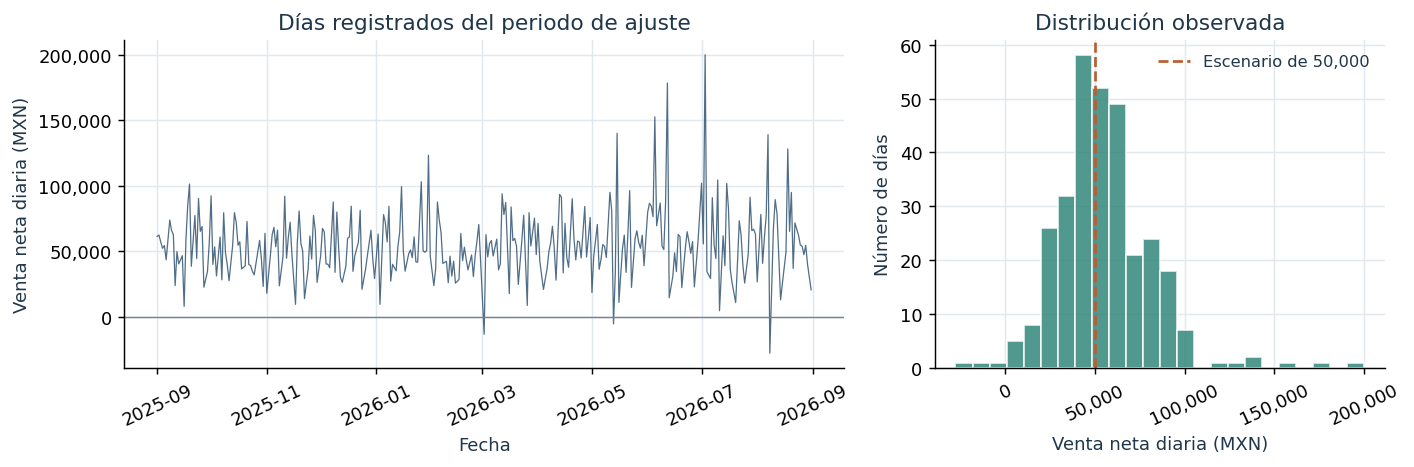

 La línea enlaza las fechas con registros. Las barras cuentan días por intervalo de importe y la línea discontinua señala el escenario de análisis.

 La asimetría observada es 1.14. Hay días de venta elevada y saldos negativos, lo que motiva una distribución con soporte real y colas amplias.

 La media y los intervalos predictivos deben incorporar la variación diaria y las diferencias de calendario.

In [50]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.7), gridspec_kw={"width_ratios": [1.6, 1]})
ejes[0].plot(ajuste["fecha"], ajuste["ventas_netas"], color=AZUL, lw=0.7, alpha=0.75)
ejes[0].axhline(0, color="#77838F", lw=0.8)
ejes[0].set(xlabel="Fecha", ylabel="Venta neta diaria (MXN)", title="Días registrados del periodo de ajuste")
ejes[0].yaxis.set_major_formatter(FORMATO_MXN)
ejes[0].tick_params(axis="x", rotation=25)
ejes[1].hist(ajuste["ventas_netas"], bins=24, color=TURQUESA, alpha=0.8, edgecolor="white")
ejes[1].axvline(UMBRAL_MXN, color=NARANJA, ls="--", label="Escenario de 50,000")
ejes[1].set(xlabel="Venta neta diaria (MXN)", ylabel="Número de días", title="Distribución observada")
ejes[1].xaxis.set_major_formatter(FORMATO_MXN)
ejes[1].tick_params(axis="x", rotation=25)
ejes[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()
display(Markdown(
    " La línea enlaza las fechas con registros. Las barras cuentan días por "
    "intervalo de importe y la línea discontinua señala el escenario de análisis.\n\n"
    f" La asimetría observada es {skew(ajuste['ventas_netas']):.2f}. "
    "Hay días de venta elevada y saldos negativos, lo que motiva una distribución con "
    "soporte real y colas amplias.\n\n"
    " La media y los intervalos predictivos deben incorporar la variación "
    "diaria y las diferencias de calendario."))

## 3. Fundamentos matemáticos y probabilísticos

### Modelo de las ventas netas

Para mejorar la escala numérica se usa $y_i=V_i/10{,}000$. Sea $d_i\in\{0,\ldots,5\}$ el día de semana, de lunes a sábado, y $g_i=\mathbf1(d_i=5)$ el indicador de sábado. Se propone

$$
y_i\mid\boldsymbol\theta\sim t_\nu(m_i,\sigma_{g_i}),\qquad \nu=5,
$$

$$
m_i=\alpha_{d_i}+\beta_t t_i+\gamma_s\sin(\omega_i)+\gamma_c\cos(\omega_i)
=\mathbf x_i^{\mathsf T}\mathbf b.
$$

Las seis $\alpha_d$ representan los niveles por día de semana. El tiempo $t_i$ se mide en años respecto del 1 de marzo de 2026. La fase anual es $\omega_i=2\pi(\text{fecha}_i-\text{1 enero 2025})/365.25$. La matriz $X$ tiene seis indicadores de día y tres columnas temporales. Se usan dos escalas positivas, una para lunes–viernes y otra para sábado, porque las jornadas presentan distinta dispersión.

Con $\nu=5$, la media condicional es $m_i$ y la varianza es $5\sigma_{g_i}^2/3$. Las colas de Student permiten acomodar observaciones alejadas del centro. El modelo supone independencia condicional dadas las variables de calendario y los parámetros.

### Posterior

Se parametriza $s_0=\log\sigma_0$ y $s_1=\log\sigma_1$. Los 11 parámetros de la cadena son $\boldsymbol\theta=(\alpha_0,\ldots,\alpha_5,\beta_t,\gamma_s,\gamma_c,s_0,s_1)\in\mathbb R^{11}$. Las previas son independientes y propias,

$$
\alpha_d\sim N(5,5^2),\quad \beta_t\sim N(0,3^2),\quad
\gamma_s,\gamma_c\sim N(0,2^2),\quad s_0,s_1\sim N(\log2,0.8^2).
$$

Por ejemplo, la previa de cada nivel diario tiene centro en 50,000 MXN y desviación estándar de 50,000 MXN. Las previas de las escalas se definen directamente en coordenadas logarítmicas.

Sea $c_\nu=\log\Gamma((\nu+1)/2)-\log\Gamma(\nu/2)-\tfrac12\log(\nu\pi)$. La log-verosimilitud es

$$
\ell(\boldsymbol\theta)=\sum_{i=1}^n\left[
c_\nu-s_{g_i}-\frac{\nu+1}{2}
\log\left(1+\frac{(y_i-\mathbf x_i^{\mathsf T}\mathbf b)^2}{\nu e^{2s_{g_i}}}\right)\right].
$$

Si $a_j$ y $h_j$ son la media y la desviación previa del coeficiente $b_j$, la distribución objetivo cumple

$$
\log\pi(\boldsymbol\theta\mid\mathbf y)=\ell(\boldsymbol\theta)
-\frac12\sum_{j=1}^9\left(\frac{b_j-a_j}{h_j}\right)^2
-\frac12\sum_{g=0}^1\left(\frac{s_g-\log2}{0.8}\right)^2+C.
$$

### Cantidades de interés

La venta media esperada para la composición de fechas del periodo de ajuste y la probabilidad media de superar el umbral se definen como

$$
\bar V(\boldsymbol\theta)=\frac{10{,}000}{n}\sum_{i=1}^n\mathbf x_i^{\mathsf T}\mathbf b,
\qquad
p_{50}(\boldsymbol\theta)=\frac1n\sum_{i=1}^n
\left[1-F_{t_5}\left(\frac{5-\mathbf x_i^{\mathsf T}\mathbf b}{\sigma_{g_i}}\right)\right].
$$

Aquí $F_{t_5}$ es la acumulada de Student estándar. El factor 10,000 devuelve las cantidades monetarias a MXN. La probabilidad predictiva es $E_\pi[p_{50}(\boldsymbol\theta)]$. Para una fecha nueva se utiliza su vector $\mathbf x_*$ y su grupo de escala.

### Cadena de Markov y estacionariedad

Una cadena de Markov cumple $P(\Theta_{t+1}\in A\mid\Theta_t,\ldots,\Theta_0)=K(\Theta_t,A)$. En MCMC se construye un núcleo homogéneo $K$ cuya distribución estacionaria es la posterior,

$$\pi(A)=\int_{\mathbb R^{11}}K(\theta,A)\,\pi(d\theta).$$

Bajo irreducibilidad, aperiodicidad y las condiciones de ergodicidad, el promedio de una función integrable $g$ aproxima su esperanza posterior. Para cuatro cadenas y $m$ estados retenidos por cadena,

$$\widehat{E_\pi[g]}=\frac1{4m}\sum_{c=1}^4\sum_{t=1}^m g(\theta_{c,t}).$$

El índice de la cadena representa iteraciones computacionales. Las fechas de venta ingresan como información del modelo.

## 4. Selección del algoritmo MCMC

Se elige **Metropolis–Hastings multivariado** porque se puede evaluar la posterior conjunta de los coeficientes y las log-escalas, y las condicionales del modelo Student requieren tratamiento numérico.

Desde el estado $\theta$, se propone $z\sim N_{11}(\theta,Q)$ con matriz $Q$ fija. La simetría de la propuesta simplifica la probabilidad de aceptación,

$$\alpha(\theta,z)=\min\left(1,\frac{\pi(z)q(\theta\mid z)}{\pi(\theta)q(z\mid\theta)}\right)
=\min\left(1,\exp[\log\pi(z)-\log\pi(\theta)]\right).$$

Se genera $U\sim U(0,1)$ y se acepta si $\log U<\min(0,\log\pi(z)-\log\pi(\theta))$. Un rechazo registra de nuevo el estado actual. La implementación trabaja en logaritmos para evitar cocientes de densidades muy pequeñas.

El núcleo de transición incluye el desplazamiento aceptado y la masa de permanencia,

$$K(\theta,A)=\int_A q(z\mid\theta)\alpha(\theta,z)\,dz+
\mathbf1_A(\theta)\left[1-\int_{\mathbb R^{11}}q(z\mid\theta)\alpha(\theta,z)\,dz\right].$$

El producto $\pi(\theta)q(z\mid\theta)\alpha(\theta,z)$ es el mínimo de $\pi(\theta)q(z\mid\theta)$ y $\pi(z)q(\theta\mid z)$. Esta simetría demuestra el balance detallado y la invariancia de la posterior. Estas propiedades proporcionan irreducibilidad y aperiodicidad para la posterior y positiva del modelo.

## 5. Configuración de la simulación

| Configuración | Valor y justificación |
|---|---|
| Periodo de ajuste | Últimos 12 meses completos anteriores al mes final de la base de datos, de septiembre de 2025 a agosto de 2026. Permiten estudiar un periodo reciente y un ciclo anual. |
| Validación temporal | Días registrados del 1 al 25 de septiembre de 2026. Se reservan desde la definición del ajuste. |
| Grados de libertad | $\nu=5$, fijados para representar colas amplias y conservar media y varianza finitas. |
| Cadenas | Cuatro, con arranques dispersos a partir de un centro posterior y subsemillas distintas. |
| Iteraciones | 20,000 propuestas por cadena. |
| Calentamiento | 4,000 estados por cadena. |
| Piloto | Tres escalas, 6,000 propuestas por escala y descarte inicial de 1,500. Se elige el mayor ESS central mínimo entre los 11 parámetros. |
| Precisión numérica | R-hat menor a 1.01, ESS central y de colas de al menos 400, MCSE de la venta media menor a 100 MXN y de la probabilidad menor a 0.5 puntos porcentuales. |

Una optimización encuentra el máximo a posteriori, usado como centro computacional. Su aproximación a la inversa de la curvatura local proporciona la forma de la propuesta. El piloto fija un multiplicador de escala. La matriz permanece constante durante todas las cadenas finales.

La siguiente celda construye la matriz de diseño, los grupos de escala y los valores previos. El periodo y el umbral se declararon al cargar los datos.

In [43]:
CENTRO_FECHA = pd.Timestamp("2026-03-01")
ORIGEN_ANUAL = pd.Timestamp("2025-01-01")
NU = 5
N_CADENAS, N_ITER, CALENTAMIENTO = 4, 20_000, 4_000
N_PILOTO, CALENTAMIENTO_PILOTO = 6_000, 1_500
FACTORES = (0.7, 1.0, 1.4)
def matriz_diseno(fechas):
    '''Indicadores de día, tiempo en años y ciclo anual para fechas lunes–sábado.'''
    dias = fechas.dt.day_of_week.to_numpy()
    if np.any(dias > 5):
        raise ValueError("El modelo está definido para los días de lunes a sábado.")
    tiempo = (fechas - CENTRO_FECHA).dt.days.to_numpy() / 365.25
    fase = 2 * np.pi * (fechas - ORIGEN_ANUAL).dt.days.to_numpy() / 365.25
    return np.column_stack([np.eye(6)[dias], tiempo, np.sin(fase), np.cos(fase)])
X = matriz_diseno(ajuste["fecha"])
y = ajuste["ventas_netas"].to_numpy() / UNIDAD
grupo = ajuste["dia"].eq(5).to_numpy().astype(int)
P = X.shape[1]
DIM = P + 2
previa_media = np.r_[np.full(6, 5.0), np.zeros(3)]
previa_de = np.r_[np.full(6, 5.0), 3.0, 2.0, 2.0]
nombres_parametros = [f"α {d}" for d in DIAS[:6]] + ["β tiempo", "γ seno", "γ coseno", "log σ L–V", "log σ sábado"]
constante_t = gammaln((NU + 1) / 2) - gammaln(NU / 2) - 0.5 * np.log(NU * np.pi)
print(f"Matriz X: {X.shape}. Espacio de la cadena: R^{DIM}.")

Matriz X: (310, 9). Espacio de la cadena: R^11.


## 6. Implementación computacional

### Posterior y verificación de la densidad

La celda implementa la log-posterior de las ecuaciones. También contrasta diferencias de log-densidad con la función Student  y con las previas normales. El contraste permite revisar que la implementación manual evalúe la distribución propuesta.

In [49]:
def log_posterior(theta):
    '''Log-posterior en coeficientes y log-escalas, salvo una constante aditiva.'''
    beta, log_escalas = theta[:P], theta[P:]
    log_sigma = log_escalas[grupo]
    with np.errstate(over="ignore", under="ignore", invalid="ignore"):
        residuo_2 = ((y - X @ beta) * np.exp(-log_sigma)) ** 2
        log_verosimilitud = np.sum(
            constante_t - log_sigma - (NU + 1) / 2 * np.log1p(residuo_2 / NU))
        log_previa = (-0.5 * np.sum(((beta - previa_media) / previa_de) ** 2)
            -0.5 * np.sum(((log_escalas - np.log(2)) / 0.8) ** 2))
        valor = log_verosimilitud + log_previa
    return float(valor) if np.isfinite(valor) else -np.inf
beta_inicial = np.linalg.lstsq(X, y, rcond=None)[0]
referencia = np.r_[beta_inicial, np.log([2.0, 1.2])]
punto_control = referencia + np.linspace(-0.08, 0.08, DIM)
def log_posterior_scipy(theta):
    beta, log_escalas = theta[:P], theta[P:]
    return (
        student_t.logpdf(y, df=NU, loc=X @ beta, scale=np.exp(log_escalas[grupo])).sum()
        + norm.logpdf(beta, loc=previa_media, scale=previa_de).sum()
        + norm.logpdf(log_escalas, loc=np.log(2), scale=0.8).sum())
error_densidad = abs(
    (log_posterior(punto_control) - log_posterior(referencia))
    - (log_posterior_scipy(punto_control) - log_posterior_scipy(referencia)))
if error_densidad > 1e-8:
    raise ArithmeticError("Revisa la implementación de la densidad posterior.")
print(f"Diferencia entre evaluaciones independientes de la log-densidad: {error_densidad:.2e}")

Diferencia entre evaluaciones independientes de la log-densidad: 0.00e+00


### Centro y forma de la propuesta

Se obtiene un centro por optimización BFGS y una matriz definida positiva a partir de la aproximación de curvatura. El factor $2.38/\sqrt{11}$ proporciona una escala inicial que se compara en el piloto.

In [14]:
optimizacion = minimize(lambda theta: -log_posterior(theta), referencia,
                       method="BFGS", options={"gtol": 1e-5})
if not optimizacion.success:
    raise RuntimeError(f"Revisa la optimización de la propuesta: {optimizacion.message}")
centro = optimizacion.x
covarianza_local = np.asarray(optimizacion.hess_inv)
covarianza_local = (covarianza_local + covarianza_local.T) / 2
L_local = np.linalg.cholesky(covarianza_local)
L_base = (2.38 / np.sqrt(DIM)) * L_local
print("Optimización completada. La propuesta incorpora las correlaciones locales entre parámetros.")

Optimización completada. La propuesta incorpora las correlaciones locales entre parámetros.


### Transición Metropolis–Hastings y piloto

La función genera desplazamientos normales correlacionados mediante la matriz de Cholesky de la propuesta. Cada fila de salida registra el estado al terminar una propuesta. Los pilotos se comparan con el mismo presupuesto de iteraciones y el menor ESS de los parámetros.

In [48]:
def metropolis_hastings(inicio, L_propuesta, iteraciones, rng):
    '''Cadena con propuesta gaussiana simétrica y matriz fija.'''
    estados = np.empty((iteraciones, DIM))
    aceptadas = np.zeros(iteraciones, dtype=bool)
    actual = np.asarray(inicio, dtype=float).copy()
    log_actual = log_posterior(actual)
    incrementos = rng.normal(size=(iteraciones, DIM)) @ L_propuesta.T
    log_uniformes = np.log1p(-rng.random(iteraciones))

    for i, (incremento, log_u) in enumerate(zip(incrementos, log_uniformes)):
        candidato = actual + incremento
        log_candidato = log_posterior(candidato)
        if log_u < min(0.0, log_candidato - log_actual):
            actual, log_actual = candidato, log_candidato
            aceptadas[i] = True
        estados[i] = actual
    return estados, aceptadas
registros_piloto = []
for factor, semilla in zip(FACTORES, sem_piloto.spawn(len(FACTORES))):
    piloto, aceptadas = metropolis_hastings(centro, factor * L_base, N_PILOTO,
                                           np.random.default_rng(semilla))
    retenido = piloto[CALENTAMIENTO_PILOTO:]
    ess = [az.ess(retenido[:, j], method="bulk") for j in range(DIM)]
    registros_piloto.append({
        "Multiplicador": factor,
        "Aceptación (%)": 100 * aceptadas[CALENTAMIENTO_PILOTO:].mean(),
        "ESS bulk mínimo": min(ess),})
pilotos = pd.DataFrame(registros_piloto)
factor_final = pilotos.loc[pilotos["ESS bulk mínimo"].idxmax(), "Multiplicador"]
L_final = factor_final * L_base
display(pilotos.round(2))
print(f"Multiplicador elegido: {factor_final:g}. La matriz queda fija para las cadenas finales.")

,Multiplicador,Aceptación (%),ESS bulk mínimo
0,0.7,42.36,93.78
1,1.0,25.96,86.39
2,1.4,12.67,49.47


Multiplicador elegido: 0.7. La matriz queda fija para las cadenas finales.


### Cuatro cadenas finales

Los valores iniciales se dispersan alrededor del centro usando tres desviaciones de la aproximación local. El cuadro muestra sus ventas medias y escalas iniciales, la tasa de aceptación posterior al calentamiento y la media estimada por cadena.

In [51]:
rng_inicio = np.random.default_rng(sem_arranque)
inicios = centro + 3 * (rng_inicio.normal(size=(N_CADENAS, DIM)) @ L_local.T)
cadenas = np.empty((N_CADENAS, N_ITER, DIM))
aceptaciones = np.empty((N_CADENAS, N_ITER), dtype=bool)

for c, semilla in enumerate(sem_cadenas.spawn(N_CADENAS)):
    cadenas[c], aceptaciones[c] = metropolis_hastings(
        inicios[c], L_final, N_ITER, np.random.default_rng(semilla))
posterior = cadenas[:, CALENTAMIENTO:, :]
beta = posterior[:, :, :P]
escalas = UNIDAD * np.exp(posterior[:, :, P:])
venta_media = UNIDAD * (beta @ X.mean(axis=0))
M = venta_media.size
display(pd.DataFrame({
    "Cadena": np.arange(1, N_CADENAS + 1),
    "Venta media inicial (MXN)": UNIDAD * (inicios[:, :P] @ X.mean(axis=0)),
    "Escala L–V inicial (MXN)": UNIDAD * np.exp(inicios[:, P]),
    "Escala sábado inicial (MXN)": UNIDAD * np.exp(inicios[:, P + 1]),
    "Aceptación (%)": 100 * aceptaciones[:, CALENTAMIENTO:].mean(axis=1),
    "Venta media MCMC (MXN)": venta_media.mean(axis=1),}).round(2))
print(f"Muestras retenidas: {M:,}, con {posterior.shape[1]:,} por cadena.")

,Cadena,Venta media inicial (MXN),Escala L–V inicial (MXN),Escala sábado inicial (MXN),Aceptación (%),Venta media MCMC (MXN)
0,1,51936.00,23409.98,7135.99,43.78,53284.96
1,2,54143.37,16917.86,9381.00,42.89,53217.36
2,3,48457.48,22060.77,13938.42,42.56,53357.94
3,4,52533.84,26193.32,10260.30,43.19,53284.62


Muestras retenidas: 64,000, con 16,000 por cadena.


### Probabilidad del escenario de venta

Se evalúa la probabilidad de superar 50,000 MXN en cada configuración posterior y se promedia sobre las fechas del ajuste. El cálculo se realiza por bloques para limitar el uso de memoria. La función de supervivencia de Student calcula el área por encima del umbral.

In [47]:
planas = posterior.reshape(-1, DIM)
p50_plana = np.empty(M)
for inicio_bloque in range(0, M, 2_000):
    final_bloque = min(inicio_bloque + 2_000, M)
    bloque = planas[inicio_bloque:final_bloque]
    medias_bloque = bloque[:, :P] @ X.T
    sigma_bloque = np.exp(bloque[:, P:])[:, grupo]
    p50_plana[inicio_bloque:final_bloque] = student_t.sf(
        (UMBRAL_MXN / UNIDAD - medias_bloque) / sigma_bloque, df=NU
    ).mean(axis=1)
p50 = p50_plana.reshape(venta_media.shape)
principales = {"Venta media (MXN)": venta_media,
               "Escala L–V (MXN)": escalas[:, :, 0],
               "Escala sábado (MXN)": escalas[:, :, 1],
               "Probabilidad > 50,000": p50}
print(f"Probabilidad predictiva estimada de superar 50,000: {100 * p50.mean():.2f} %")

Probabilidad predictiva estimada de superar 50,000: 55.52 %


## 7. Diagnóstico de convergencia

| Diagnóstico | Significado y referencia de interpretación |
|---|---|
| R-hat | Compara la variación dentro y entre cadenas divididas. Se usa la versión normalizada por rangos y plegada, con referencia menor a 1.01. |
| ESS *bulk* | Cantidad equivalente de muestras independientes para el centro de la distribución. |
| ESS *tail* | Eficiencia en las colas, calculada a partir de los cuantiles 0.05 y 0.95. |
| MCSE | Error estándar por el tamaño finito y la dependencia de la simulación, específico de cada estimación. |
| Trayectorias y ACF | Permiten inspeccionar estabilidad, exploración y persistencia entre estados consecutivos. |

Los valores son referencias prácticas que se interpretan junto con las gráficas. Los diagnósticos proporcionan evidencia empírica con cadenas finitas.

La celda evalúa los 11 parámetros y las cuatro cantidades principales para verificar también la precisión de los resultados que se comunicarán.

In [52]:
todas = {nombre: posterior[:, :, j] for j, nombre in enumerate(nombres_parametros)}
todas.update(principales)
filas_diagnostico = []
for nombre, matriz in todas.items():
    filas_diagnostico.append({
        "Cantidad": nombre, "R-hat": az.rhat(matriz, method="rank"),
        "ESS bulk": az.ess(matriz, method="bulk"),
        "ESS tail": az.ess(matriz, method="tail"),
        "MCSE de la media": np.asarray(az.mcse(matriz, method="mean")).item(),})
diagnosticos = pd.DataFrame(filas_diagnostico).set_index("Cantidad")
display(diagnosticos.round({"R-hat": 5, "ESS bulk": 0, "ESS tail": 0, "MCSE de la media": 5}))
max_rhat = diagnosticos["R-hat"].max()
min_ess = diagnosticos[["ESS bulk", "ESS tail"]].min().min()
mcse_media = diagnosticos.loc["Venta media (MXN)", "MCSE de la media"]
mcse_p50 = diagnosticos.loc["Probabilidad > 50,000", "MCSE de la media"]
cumple = max_rhat < 1.01 and min_ess >= 400 and mcse_media < 100 and mcse_p50 < 0.005
estado = "Se satisfacen los criterios numéricos establecidos." if cumple else "Se requiere revisar los criterios numéricos pendientes."
display(Markdown(
    f"El mayor R-hat es {max_rhat:.5f} y el menor ESS es {min_ess:,.0f}. "
    f"El MCSE de la venta media es {mcse_media:,.2f} MXN, y el de la probabilidad es "
    f"{100 * mcse_p50:.3f} puntos porcentuales. {estado}"))

,R-hat,ESS bulk,ESS tail,MCSE de la media
Cantidad,,,,
α Lunes,1.00147,1541.0,2370.0,0.00795
α Martes,1.00353,1591.0,3771.0,0.00754
α Miércoles,1.00283,1677.0,2993.0,0.00713
α Jueves,1.00621,1247.0,2681.0,0.00842
α Viernes,1.00293,1513.0,3312.0,0.00818
α Sábado,1.00417,1436.0,2629.0,0.00586
β tiempo,1.00309,1380.0,2778.0,0.01693
γ seno,1.00262,1432.0,2294.0,0.00528
γ coseno,1.00123,1440.0,2702.0,0.00620


El mayor R-hat es 1.00621 y el menor ESS es 1,064. El MCSE de la venta media es 37.03 MXN, y el de la probabilidad es 0.068 puntos porcentuales. Se satisfacen los criterios numéricos establecidos.

### Trayectorias de las cadenas

Se muestran la venta media esperada y la escala de lunes a viernes. La columna izquierda presenta las primeras 250 iteraciones, incluido el arranque. La derecha muestra 700 iteraciones consecutivas después del calentamiento.

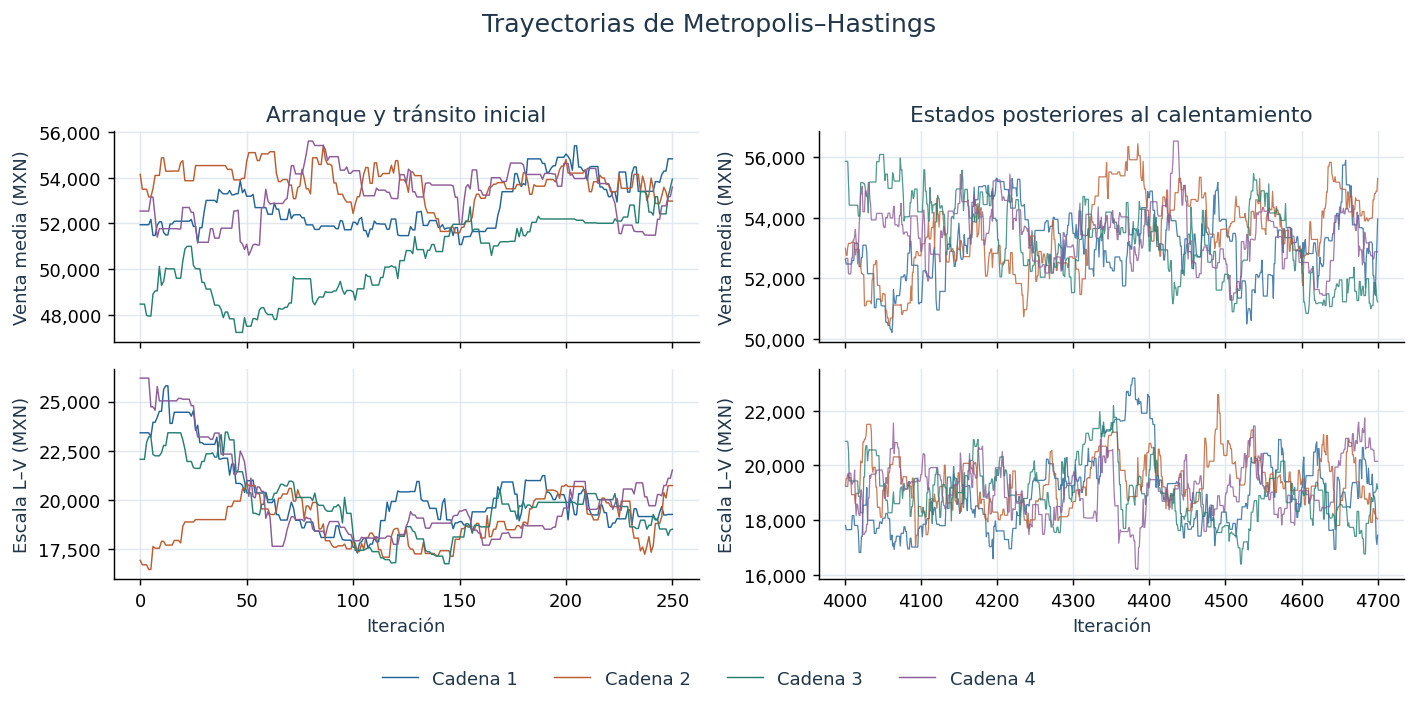

Cada color identifica una cadena iniciada en un estado distinto.

 Los arranques llegan a una zona común. Las medias por cadena se ubican entre 53,217 y 53,358 MXN. La ventana posterior muestra exploración repetida de niveles similares.

 El acuerdo entre arranques respalda la estabilidad computacional de la estimación de venta diaria media.

In [53]:
tray_media = UNIDAD * (cadenas[:, :, :P] @ X.mean(axis=0))
tray_sigma = UNIDAD * np.exp(cadenas[:, :, P])
iniciales_plot = [UNIDAD * (inicios[:, :P] @ X.mean(axis=0)), UNIDAD * np.exp(inicios[:, P])]
fig, ejes = plt.subplots(2, 2, figsize=(11, 5.4), sharex="col")
for j, (matriz, etiqueta) in enumerate(zip([tray_media, tray_sigma],
                                         ["Venta media (MXN)", "Escala L–V (MXN)"])):
    for c, color in enumerate(COLORES):
        arranque = np.r_[iniciales_plot[j][c], matriz[c, :250]]
        ejes[j, 0].plot(np.arange(251), arranque, color=color, lw=0.8, label=f"Cadena {c + 1}")
        ejes[j, 1].plot(np.arange(CALENTAMIENTO + 1, CALENTAMIENTO + 701),
                        matriz[c, CALENTAMIENTO:CALENTAMIENTO + 700], color=color, lw=0.7, alpha=0.8)
    for eje in ejes[j]:
        eje.set_ylabel(etiqueta)
        eje.yaxis.set_major_formatter(FORMATO_MXN)
ejes[0, 0].set_title("Arranque y tránsito inicial")
ejes[0, 1].set_title("Estados posteriores al calentamiento")
for eje in ejes[-1]:
    eje.set_xlabel("Iteración")
fig.suptitle("Trayectorias de Metropolis–Hastings", fontsize=14)
fig.legend(*ejes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.065, 1, 0.94))
plt.show()
medias_cadenas = venta_media.mean(axis=1)
display(Markdown(
    "Cada color identifica una cadena iniciada en un estado distinto.\n\n"
    f" Los arranques llegan a una zona común. Las medias por cadena "
    f"se ubican entre {medias_cadenas.min():,.0f} y {medias_cadenas.max():,.0f} MXN. "
    "La ventana posterior muestra exploración repetida de niveles similares.\n\n"
    " El acuerdo entre arranques respalda la estabilidad computacional "
    "de la estimación de venta diaria media."))

###  Autocorrelación de las muestras MCMC

La ACF se calcula sobre todos los estados retenidos para la venta media, la escala de lunes a viernes y la probabilidad del escenario. Las curvas describen dependencia entre iteraciones de las cadenas.

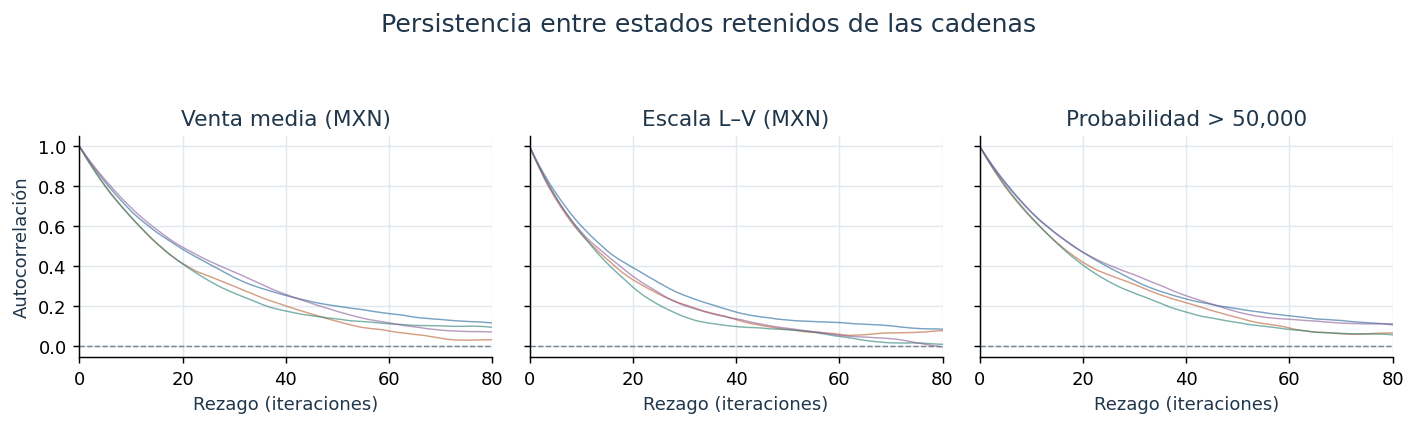

Las cuatro curvas de cada panel corresponden a las cuatro cadenas.

 La ACF media de la venta esperada es 0.96 en el rezago 1 y 0.115 en el rezago 60. La dependencia reduce la cantidad de información respecto del número total de estados almacenados.

ESS y MCSE permiten expresar la precisión de las estimaciones considerando esta dependencia.

In [54]:
seleccion_acf = ["Venta media (MXN)", "Escala L–V (MXN)", "Probabilidad > 50,000"]
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.3), sharey=True)
acf_cantidades = {}
for eje, nombre in zip(ejes, seleccion_acf):
    acf = az.autocorr(principales[nombre], axis=1)[:, :81]
    acf_cantidades[nombre] = acf.mean(axis=0)
    for c, color in enumerate(COLORES):
        eje.plot(np.arange(81), acf[c], color=color, lw=0.8, alpha=0.6)
    eje.axhline(0, color="#77838F", ls="--", lw=0.8)
    eje.set(xlabel="Rezago (iteraciones)", title=nombre, xlim=(0, 80))
ejes[0].set_ylabel("Autocorrelación")
fig.suptitle("Persistencia entre estados retenidos de las cadenas", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()
acf_media = acf_cantidades["Venta media (MXN)"]
display(Markdown(
    "Las cuatro curvas de cada panel corresponden a las cuatro cadenas.\n\n"
    f" La ACF media de la venta esperada es {acf_media[1]:.2f} en el "
    f"rezago 1 y {acf_media[60]:.3f} en el rezago 60. La dependencia reduce la cantidad "
    "de información respecto del número total de estados almacenados.\n\n"
    "ESS y MCSE permiten expresar la precisión de las estimaciones "
    "considerando esta dependencia."))

## 8. Resultados numéricos

### Estimaciones posteriores

La celda resume las distribuciones de las cuatro cantidades principales. Los percentiles 2.5 y 97.5 forman intervalos centrales de credibilidad del 95 %. La varianza de cada distribución posterior se expresa en el cuadrado de la unidad indicada para la cantidad.

In [57]:
filas = []
for nombre, matriz in principales.items():
    valores = matriz.ravel()
    q025, q25, mediana, q75, q975 = np.quantile(valores, [0.025, 0.25, 0.5, 0.75, 0.975])
    filas.append({"Cantidad": nombre, "Media": valores.mean(), "Mediana": mediana,
                  "DE posterior": valores.std(ddof=1), "Varianza posterior": valores.var(ddof=1),
                  "P2.5": q025, "P25": q25, "P75": q75, "P97.5": q975})
resumen = pd.DataFrame(filas).set_index("Cantidad")
display(resumen.round(5))
r_media = resumen.loc["Venta media (MXN)"]
r_prob = resumen.loc["Probabilidad > 50,000"]
display(Markdown(
    f"La venta media esperada para la composición de fechas del periodo se estima en "
    f"{r_media['Media']:,.2f} MXN, con credibilidad del 95 % de "
    f"{r_media['P2.5']:,.2f} a {r_media['P97.5']:,.2f} MXN. "
    f"La probabilidad predictiva de superar 50,000 MXN es {100 * r_prob['Media']:.2f} %. "
    f"La incertidumbre sobre la probabilidad se expresa con el intervalo de "
    f"{100 * r_prob['P2.5']:.2f} % a {100 * r_prob['P97.5']:.2f} %."))

,Media,Mediana,DE posterior,Varianza posterior,P2.5,P25,P75,P97.5
Cantidad,,,,,,,,
Venta media (MXN),53296.09619,53285.55529,1221.45146,1.491944e+06,50959.88764,52481.45790,54087.72401,55770.41920
Escala L–V (MXN),19045.60234,19022.60634,1115.93449,1.245310e+06,16935.84174,18273.81955,19783.37952,21279.48934
Escala sábado (MXN),13810.94257,13649.27318,1871.03490,3.500772e+06,10640.94353,12506.30080,14945.11512,17993.25900
"Probabilidad > 50,000",0.55517,0.55501,0.02232,5.000000e-04,0.51199,0.54024,0.57028,0.59944


La venta media esperada para la composición de fechas del periodo se estima en 53,296.10 MXN, con credibilidad del 95 % de 50,959.89 a 55,770.42 MXN. La probabilidad predictiva de superar 50,000 MXN es 55.52 %. La incertidumbre sobre la probabilidad se expresa con el intervalo de 51.20 % a 59.94 %.

### Predicción para una fecha y evaluación temporal

Para cada estado posterior se agrega una innovación Student con la escala correspondiente. Así se incorpora la incertidumbre de los parámetros y la variación diaria. Los intervalos de credibilidad de la media se calculan con las medias condicionales. Los intervalos predictivos incluyen las innovaciones.

Se predicen las 22 fechas registradas de septiembre de 2026. Como referencia de comparación se usa la media histórica de cada día de semana, calculada con los mismos datos de ajuste. Se informan MAE, RMSE y cobertura del intervalo predictivo.

Además, se genera una venta comparable por estado posterior, eligiendo aleatoriamente una de las fechas del ajuste. Sus estadísticos describen la dispersión de una venta individual e incorporan incertidumbre sobre los parámetros.

In [60]:
rng_pred = np.random.default_rng(sem_pred)
X_validacion = matriz_diseno(validacion["fecha"])
grupo_validacion = validacion["fecha"].dt.day_of_week.eq(5).to_numpy().astype(int)
medias_validacion = UNIDAD * (planas[:, :P] @ X_validacion.T)
sigmas_validacion = UNIDAD * np.exp(planas[:, P:])[:, grupo_validacion]
ventas_predichas = medias_validacion + sigmas_validacion * rng_pred.standard_t(
    df=NU, size=medias_validacion.shape)
limites_pred = np.quantile(ventas_predichas, [0.025, 0.975], axis=0)
limites_media = np.quantile(medias_validacion, [0.025, 0.975], axis=0)
evaluacion = validacion[["fecha", "ventas_netas"]].reset_index(drop=True)
evaluacion["Media predicha"] = medias_validacion.mean(axis=0)
evaluacion["P2.5 predictivo"], evaluacion["P97.5 predictivo"] = limites_pred
evaluacion["P2.5 media"], evaluacion["P97.5 media"] = limites_media
medias_historicas = ajuste.groupby("dia")["ventas_netas"].mean()
evaluacion["Referencia por día"] = evaluacion["fecha"].dt.day_of_week.map(medias_historicas)
observadas_validacion = evaluacion["ventas_netas"].to_numpy()
error_modelo = observadas_validacion - evaluacion["Media predicha"].to_numpy()
error_referencia = observadas_validacion - evaluacion["Referencia por día"].to_numpy()
dentro = (observadas_validacion >= limites_pred[0]) & (observadas_validacion <= limites_pred[1])
metricas = pd.DataFrame({
    "Método": ["Regresión Student MCMC", "Media histórica por día de semana"],
    "MAE (MXN)": [np.abs(error_modelo).mean(), np.abs(error_referencia).mean()],
    "RMSE (MXN)": [np.sqrt(np.mean(error_modelo ** 2)), np.sqrt(np.mean(error_referencia ** 2))],
}).set_index("Método")
display(metricas.round(2))
display(evaluacion.head(8).assign(fecha=lambda tabla: tabla["fecha"].dt.strftime("%Y-%m-%d")).round(2))
display(Markdown(
    f"El intervalo predictivo del 95 % cubre **{dentro.sum()} de {len(dentro)}** ventas "
    f"posteriores ({100 * dentro.mean():.1f} %), con amplitud media de "
    f"{np.diff(limites_pred, axis=0).mean():,.0f} MXN. El MAE del modelo es "
    f"{np.abs(error_modelo).mean():,.0f} MXN. La evaluación corresponde a este conjunto "
    "corto de fechas posteriores."))
fechas_sorteadas = rng_pred.integers(0, n, size=M)
medias_nuevas = UNIDAD * np.einsum("ij,ij->i", planas[:, :P], X[fechas_sorteadas])
sigmas_nuevas = UNIDAD * np.exp(planas[:, P:])[np.arange(M), grupo[fechas_sorteadas]]
ventas_nuevas = medias_nuevas + sigmas_nuevas * rng_pred.standard_t(NU, size=M)
resumen_ventas = []
for origen, valores in [("Ventas observadas", ajuste["ventas_netas"].to_numpy()),
                        ("Ventas predictivas comparables", ventas_nuevas)]:
    resumen_ventas.append({"Origen": origen, "Media (MXN)": valores.mean(), "Mediana (MXN)": np.median(valores),
        "DE (MXN)": valores.std(ddof=1), "Varianza (MXN²)": valores.var(ddof=1),
        "P2.5 (MXN)": np.quantile(valores, 0.025), "P97.5 (MXN)": np.quantile(valores, 0.975),})
display(pd.DataFrame(resumen_ventas).set_index("Origen").round(2))
q_predictivo = np.quantile(ventas_nuevas, [0.025, 0.975])
display(Markdown(
    f"Para un día registrado comparable al periodo de ajuste, el intervalo predictivo "
    f"del 95 % es de {q_predictivo[0]:,.0f} a {q_predictivo[1]:,.0f} MXN. "
    "Su amplitud refleja la variación entre ventas individuales y la incertidumbre "
    "de los parámetros."))

,MAE (MXN),RMSE (MXN)
Método,,
Regresión Student MCMC,14429.05,17748.39
Media histórica por día de semana,16255.60,19227.59


,fecha,ventas_netas,Media predicha,P2.5 predictivo,P97.5 predictivo,P2.5 media,P97.5 media,Referencia por día
0,2026-09-01,91601.00,58440.95,8362.42,107960.88,48754.20,68401.61,60107.54
1,2026-09-02,62852.31,56120.57,5881.17,106060.96,46765.13,65488.70,57565.73
2,2026-09-03,48177.00,57747.63,7748.07,107291.05,48188.84,67043.64,59194.74
3,2026-09-04,52109.00,55522.75,5796.59,105577.17,45479.48,65636.26,66227.40
4,2026-09-05,30042.00,32187.39,-4570.91,69499.74,22983.51,41412.37,33431.90
5,2026-09-07,25846.00,52605.00,2280.24,102232.96,42877.07,62569.18,53774.50
6,2026-09-08,51055.01,57959.64,7617.15,108148.69,47850.08,68392.32,60107.54
7,2026-09-09,38262.00,55638.77,5834.66,105987.02,45853.34,65454.40,57565.73


El intervalo predictivo del 95 % cubre **22 de 22** ventas posteriores (100.0 %), con amplitud media de 96,528 MXN. El MAE del modelo es 14,429 MXN. La evaluación corresponde a este conjunto corto de fechas posteriores.

,Media (MXN),Mediana (MXN),DE (MXN),Varianza (MXN²),P2.5 (MXN),P97.5 (MXN)
Origen,,,,,,
Ventas observadas,54983.39,53417.00,26541.16,7.044331e+08,10435.68,103455.96
Ventas predictivas comparables,53276.26,53195.75,25425.22,6.464417e+08,4310.84,104832.54


Para un día registrado comparable al periodo de ajuste, el intervalo predictivo del 95 % es de 4,311 a 104,833 MXN. Su amplitud refleja la variación entre ventas individuales y la incertidumbre de los parámetros.

## 9. Resultados gráficos

###  Distribuciones posteriores de las cantidades de interés

Los histogramas muestran las muestras retenidas de la venta media, la escala de lunes a viernes y la probabilidad del escenario. Las bandas abarcan los intervalos centrales de credibilidad del 95 %.

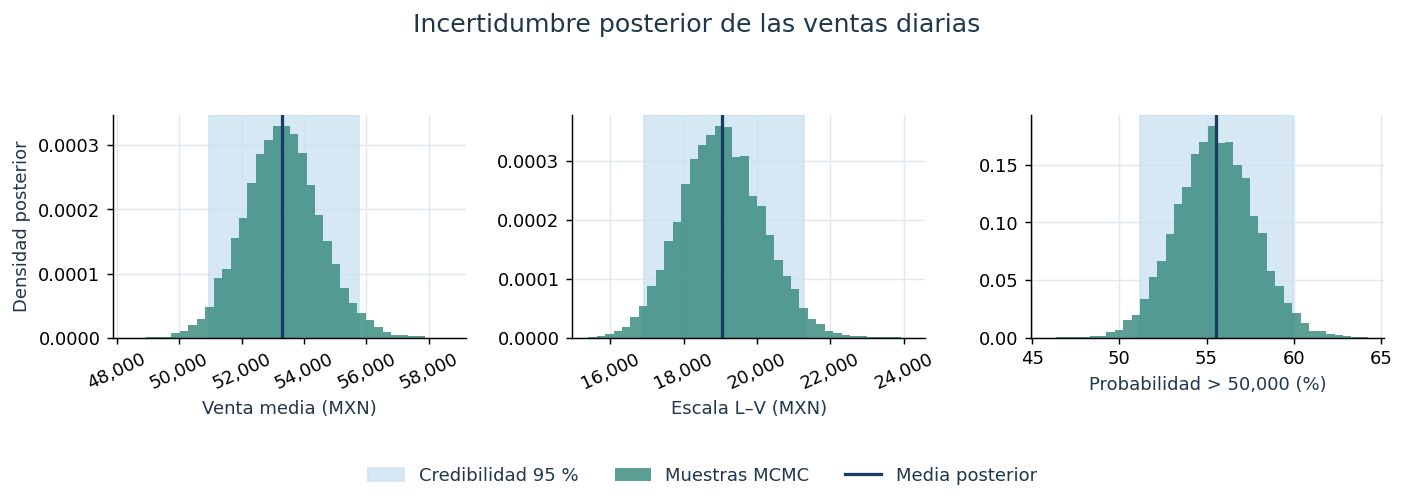

 Las barras representan las densidades posteriores, las líneas marcan las medias y las bandas los percentiles 2.5 y 97.5.

 La media diaria se concentra alrededor de 53,296 MXN. Su desviación posterior es 1,221 MXN. La escala residual describe la dispersión de las ventas condicionada al calendario.

 El escenario de 50,000 MXN tiene una probabilidad predictiva de 55.5 %, con incertidumbre estadística cuantificada por su posterior.

In [61]:
seleccion_posterior = ["Venta media (MXN)", "Escala L–V (MXN)", "Probabilidad > 50,000"]
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.8))
for eje, nombre, factor in zip(ejes, seleccion_posterior, [1, 1, 100]):
    valores = principales[nombre].ravel() * factor
    fila = resumen.loc[nombre] * factor
    eje.axvspan(fila["P2.5"], fila["P97.5"], color="#C9E1F0", alpha=0.75,
                label="Credibilidad 95 %")
    eje.hist(valores, bins=38, density=True, color=TURQUESA, alpha=0.75,
             label="Muestras MCMC")
    eje.axvline(fila["Media"], color=AZUL, lw=1.8, label="Media posterior")
    eje.set_xlabel(nombre + (" (%)" if factor == 100 else ""))
    if factor == 1:
        eje.xaxis.set_major_formatter(FORMATO_MXN)
        eje.tick_params(axis="x", rotation=25)
ejes[0].set_ylabel("Densidad posterior")
fig.suptitle("Incertidumbre posterior de las ventas diarias", fontsize=14)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.12, 1, 0.90))
plt.show()
display(Markdown(" Las barras representan las densidades posteriores, las líneas marcan "
    "las medias y las bandas los percentiles 2.5 y 97.5.\n\n"
    f" La media diaria se concentra alrededor de {r_media['Media']:,.0f} MXN. "
    f"Su desviación posterior es {r_media['DE posterior']:,.0f} MXN. La escala residual "
    "describe la dispersión de las ventas condicionada al calendario.\n\n"
    f" El escenario de 50,000 MXN tiene una probabilidad predictiva de "
    f"{100 * p50.mean():.1f} %, con incertidumbre estadística cuantificada por su posterior."))

### Venta esperada y variación predictiva por día de semana

Para cada día de semana se promedian las medias del modelo sobre las fechas de ese grupo en el ajuste. Para la predicción se selecciona aleatoriamente una de esas fechas por cada estado posterior y se genera una venta Student. La tabla y la figura permiten comparar la estimación de la media con la amplitud de la distribución de una venta individual.

,Media esperada,Credibilidad 2.5 %,Credibilidad 97.5 %,Predictivo 2.5 %,Predictivo 97.5 %
Día,,,,,
Lunes,54061.31,47878.88,60327.42,4162.49,103559.18
Martes,59495.59,53391.02,65636.81,8855.30,108905.14
Miércoles,57235.62,51574.77,62913.63,7355.54,107727.67
Jueves,59035.30,53248.25,64828.04,9126.92,108525.30
Viernes,56736.59,50511.39,63180.86,7384.00,106562.71
Sábado,33484.35,29114.95,37970.95,-3013.01,70036.33


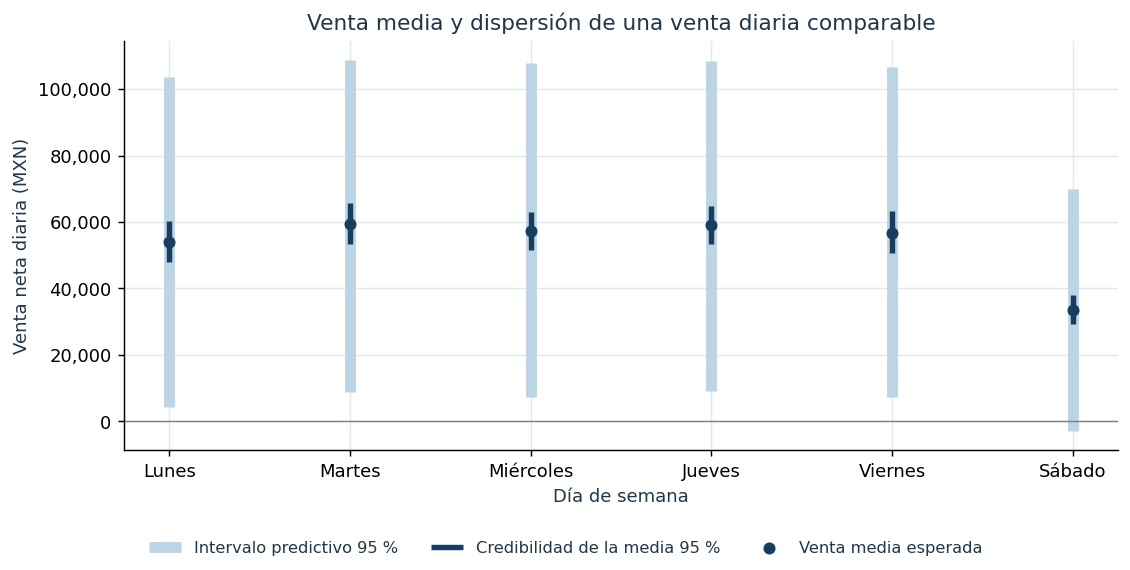

 Los puntos representan medias posteriores. Las barras oscuras muestran incertidumbre sobre la media y las claras la variación predictiva de una venta.

La venta esperada media de lunes a viernes es 57,289 MXN y la del sábado es 33,484 MXN. Las barras predictivas son más amplias porque incorporan la variación residual.

La referencia de venta diaria debe considerar el día de la semana.

In [63]:
filas_dias = []
for d in range(6):
    indices_dia = np.flatnonzero(ajuste["dia"].to_numpy() == d)
    medias_dia = UNIDAD * (planas[:, :P] @ X[indices_dia].mean(axis=0))
    fechas_elegidas = rng_pred.choice(indices_dia, size=M)
    media_individual = UNIDAD * np.einsum("ij,ij->i", planas[:, :P], X[fechas_elegidas])
    escala_dia = UNIDAD * np.exp(planas[:, P + int(d == 5)])
    predictiva_dia = media_individual + escala_dia * rng_pred.standard_t(NU, size=M)
    filas_dias.append({
        "Día": DIAS[d], "Media esperada": medias_dia.mean(),
        "Credibilidad 2.5 %": np.quantile(medias_dia, 0.025),
        "Credibilidad 97.5 %": np.quantile(medias_dia, 0.975),
        "Predictivo 2.5 %": np.quantile(predictiva_dia, 0.025),
        "Predictivo 97.5 %": np.quantile(predictiva_dia, 0.975),})
por_dia = pd.DataFrame(filas_dias).set_index("Día")
display(por_dia.round(2))
posiciones = np.arange(6)
fig, eje = plt.subplots(figsize=(8.8, 4.4))
eje.vlines(posiciones, por_dia["Predictivo 2.5 %"], por_dia["Predictivo 97.5 %"],
           color="#BCD4E3", lw=6, label="Intervalo predictivo 95 %")
eje.vlines(posiciones, por_dia["Credibilidad 2.5 %"], por_dia["Credibilidad 97.5 %"],
           color=AZUL, lw=3, label="Credibilidad de la media 95 %")
eje.scatter(posiciones, por_dia["Media esperada"], color=AZUL, s=32, zorder=3,
            label="Venta media esperada")
eje.axhline(0, color="#77838F", lw=0.8)
eje.set(xticks=posiciones, xticklabels=DIAS[:6], xlabel="Día de semana",
        ylabel="Venta neta diaria (MXN)", title="Venta media y dispersión de una venta diaria comparable")
eje.yaxis.set_major_formatter(FORMATO_MXN)
fig.legend(*eje.get_legend_handles_labels(), frameon=False, fontsize=9,
           loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
media_laborables = UNIDAD * (planas[:, :P] @ X[grupo == 0].mean(axis=0))
media_sabado = UNIDAD * (planas[:, :P] @ X[grupo == 1].mean(axis=0))
display(Markdown(
    " Los puntos representan medias posteriores. Las barras oscuras "
    "muestran incertidumbre sobre la media y las claras la variación predictiva de una venta.\n\n"
    f"La venta esperada media de lunes a viernes es "
    f"{media_laborables.mean():,.0f} MXN y la del sábado es {media_sabado.mean():,.0f} MXN. "
    "Las barras predictivas son más amplias porque incorporan la variación residual.\n\n"
    "La referencia de venta diaria debe considerar el día de la semana."))

###  Comprobación del modelo

Se generan 1,500 conjuntos replicados de 310 ventas con las mismas fechas del ajuste. Se contrastan media, percentil 95, asimetría y cantidad de saldos negativos con los datos observados. También se revisa la ACF de los residuos estandarizados por la escala posterior media. La ACF residual usa el orden de los días registrados.

,Observado,Mediana replicada,Replicado P2.5,Replicado P97.5
Resumen,,,,
Media (MXN),54983.393,53345.680,49834.316,56886.409
Percentil 95 (MXN),94476.850,93132.307,85618.560,101819.646
Asimetría,1.139,0.083,-0.919,0.975
Número de saldos negativos,3.000,5.000,1.000,11.000


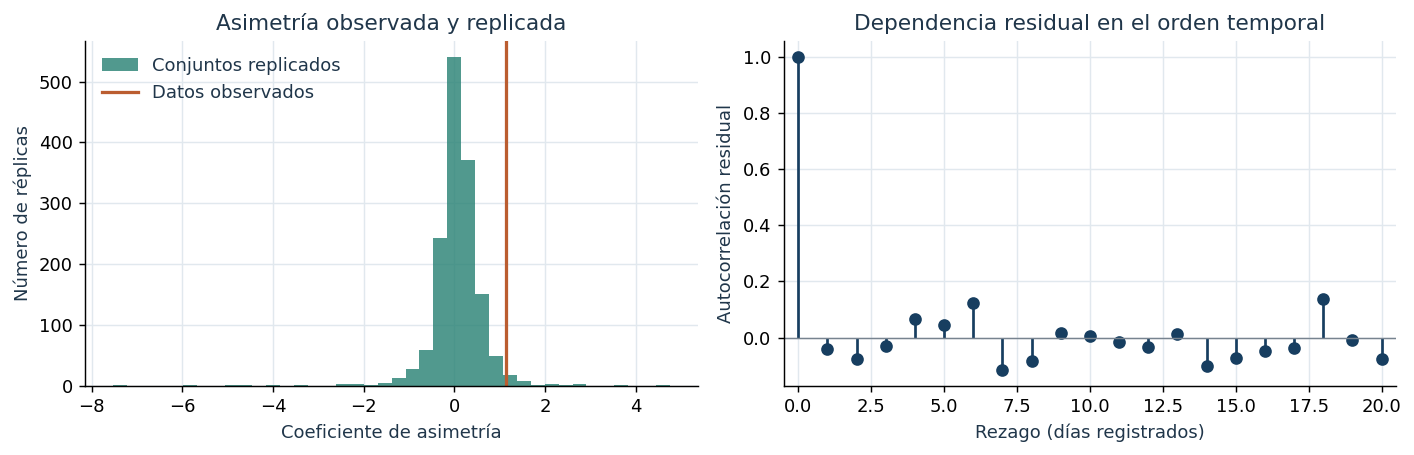

El histograma compara la asimetría de datos replicados con la observada. El segundo panel muestra la autocorrelación de residuos.

La asimetría observada es 1.14, frente a una mediana replicada de 0.08. La autocorrelación residual al rezago 1 es -0.043. Estos resultados permiten revisar la forma distributiva y la independencia condicional.

 La convergencia de MCMC se complementa con esta revisión del modelo. La cola de ventas elevadas merece atención al interpretar su capacidad predictiva.

In [65]:
ids_rep = rng_pred.choice(M, size=1_500, replace=False)
beta_rep = planas[ids_rep, :P]
medias_rep = UNIDAD * (beta_rep @ X.T)
sigmas_rep = UNIDAD * np.exp(planas[ids_rep, P:])[:, grupo]
replicas = medias_rep + sigmas_rep * rng_pred.standard_t(NU, size=medias_rep.shape)
observado = ajuste["ventas_netas"].to_numpy()
resumenes_observados = np.array([observado.mean(), np.quantile(observado, 0.95),
                                skew(observado), (observado < 0).sum()])
resumenes_rep = np.column_stack([replicas.mean(axis=1), np.quantile(replicas, 0.95, axis=1),
                                skew(replicas, axis=1), (replicas < 0).sum(axis=1)])
rep025, rep50, rep975 = np.quantile(resumenes_rep, [0.025, 0.5, 0.975], axis=0)
comprobacion = pd.DataFrame({
    "Resumen": ["Media (MXN)", "Percentil 95 (MXN)", "Asimetría", "Número de saldos negativos"],
    "Observado": resumenes_observados, "Mediana replicada": rep50,
    "Replicado P2.5": rep025, "Replicado P97.5": rep975,
}).set_index("Resumen")
display(comprobacion.round(3))

mu_ajuste = UNIDAD * (planas[:, :P].mean(axis=0) @ X.T)
sigma_ajuste = escalas.mean(axis=(0, 1))[grupo]
residuos = (observado - mu_ajuste) / sigma_ajuste
acf_residuos = az.autocorr(residuos)[:21]
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(resumenes_rep[:, 2], bins=40, color=TURQUESA, alpha=0.8,
             label="Conjuntos replicados")
ejes[0].axvline(resumenes_observados[2], color=NARANJA, lw=1.8, label="Datos observados")
ejes[0].set(xlabel="Coeficiente de asimetría", ylabel="Número de réplicas",
            title="Asimetría observada y replicada")
ejes[0].legend(frameon=False)
ejes[1].stem(np.arange(21), acf_residuos, linefmt=AZUL, markerfmt="o", basefmt=" ")
ejes[1].axhline(0, color="#77838F", lw=0.8)
ejes[1].set(xlabel="Rezago (días registrados)", ylabel="Autocorrelación residual",
            title="Dependencia residual en el orden temporal", xlim=(-0.5, 20.5))
fig.tight_layout()
plt.show()
display(Markdown(
    "El histograma compara la asimetría de datos replicados con la observada. "
    "El segundo panel muestra la autocorrelación de residuos.\n\n"
    f"La asimetría observada es {resumenes_observados[2]:.2f}, frente a "
    f"una mediana replicada de {rep50[2]:.2f}. La autocorrelación residual al rezago 1 "
    f"es {acf_residuos[1]:.3f}. Estos resultados permiten revisar la forma distributiva "
    "y la independencia condicional.\n\n"
    " La convergencia de MCMC se complementa con esta revisión del modelo. "
    "La cola de ventas elevadas merece atención al interpretar su capacidad predictiva."))

###  Predicción en las fechas reservadas

Se representan las ventas observadas de septiembre, las medias predichas y los intervalos predictivos del 95 %. Todas las predicciones utilizan la posterior ajustada con datos hasta el 31 de agosto de 2026.

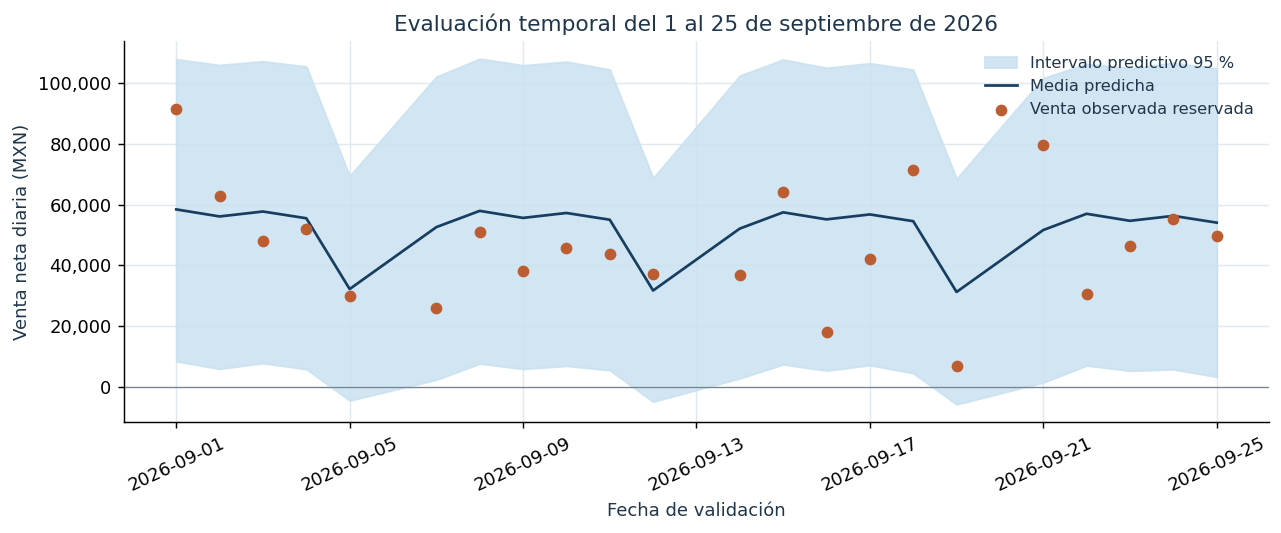

 Los puntos son ventas reservadas. La línea y la banda se calcularon con información disponible al terminar agosto.

 El MAE es 14,429 MXN y el RMSE es 17,748 MXN. El intervalo cubre 22 de 22 observaciones. La tabla permite comparar el error con una referencia por día de semana.

 La evaluación cuantifica el desempeño en fechas posteriores y debe ampliarse al disponer de más días observados.

In [66]:
fig, eje = plt.subplots(figsize=(10, 4.2))
eje.fill_between(evaluacion["fecha"], evaluacion["P2.5 predictivo"],
                  evaluacion["P97.5 predictivo"], color="#C9E1F0", alpha=0.85,
                  label="Intervalo predictivo 95 %")
eje.plot(evaluacion["fecha"], evaluacion["Media predicha"], color=AZUL, lw=1.5,
          label="Media predicha")
eje.scatter(evaluacion["fecha"], evaluacion["ventas_netas"], color=NARANJA, s=30,
             zorder=3, label="Venta observada reservada")
eje.axhline(0, color="#77838F", lw=0.7)
eje.set(xlabel="Fecha de validación", ylabel="Venta neta diaria (MXN)",
        title="Evaluación temporal del 1 al 25 de septiembre de 2026")
eje.yaxis.set_major_formatter(FORMATO_MXN)
eje.tick_params(axis="x", rotation=25)
eje.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()
display(Markdown(" Los puntos son ventas reservadas. La línea y la banda se calcularon "
    "con información disponible al terminar agosto.\n\n"
    f" El MAE es {np.abs(error_modelo).mean():,.0f} MXN y el RMSE es "
    f"{np.sqrt(np.mean(error_modelo ** 2)):,.0f} MXN. El intervalo cubre "
    f"{dentro.sum()} de {len(dentro)} observaciones. La tabla permite comparar el error "
    "con una referencia por día de semana.\n\n"
    " La evaluación cuantifica el desempeño en fechas posteriores "
    "y debe ampliarse al disponer de más días observados."))

## 10. Interpretación y conclusiones

La siguiente síntesis conecta las estimaciones, la precisión numérica y la evaluación temporal con la pregunta del estudio. Las cifras se calculan desde las salidas de la ejecución.

In [67]:
ajuste_asimetria = rep025[2] <= resumenes_observados[2] <= rep975[2]
texto_asimetria = (
    "La asimetría observada queda dentro del intervalo central de los conjuntos replicados."
    if ajuste_asimetria else
    "La asimetría observada queda fuera del intervalo central de los conjuntos replicados."
)
mejor_mae = metricas["MAE (MXN)"].idxmin()
texto_diagnosticos = (
    "Los criterios de convergencia y precisión fijados se satisfacen."
    if cumple else "Quedan criterios de convergencia o precisión por revisar."
)
display(Markdown(
    f"**Venta diaria.** La media esperada en los días registrados del periodo se estima "
    f"en **{r_media['Media']:,.0f} MXN**, con credibilidad del 95 % de "
    f"**{r_media['P2.5']:,.0f} a {r_media['P97.5']:,.0f} MXN**. El promedio aritmético "
    f"observado fue {media_observada:,.0f} MXN. La estimación incorpora los efectos "
    "de calendario y la distribución Student propuesta. Su verosimilitud da menor influencia "
    "a los residuos muy grandes.\n\n"
    f"**Escenario de venta.** La probabilidad predictiva de superar 50,000 MXN es "
    f"**{100 * p50.mean():.1f} %**, para la composición de fechas del ajuste. Los resultados "
    "por día de semana aportan referencias más específicas para la planeación diaria.\n\n"
    f"**Convergencia y precisión.** {texto_diagnosticos} El MCSE de la media, "
    f"{mcse_media:,.0f} MXN, cuantifica la variación atribuible al muestreo de la posterior. "
    f"La desviación posterior de {r_media['DE posterior']:,.0f} MXN expresa la "
    "incertidumbre estadística sobre la venta media.\n\n"
    f"**Evaluación del modelo.** {texto_asimetria} En las fechas posteriores, el menor "
    f"MAE correspondió a **{mejor_mae}**. La cobertura predictiva fue de "
    f"{dentro.sum()}/{len(dentro)}, con un ancho medio de "
    f"{np.diff(limites_pred, axis=0).mean():,.0f} MXN."
))

**Venta diaria.** La media esperada en los días registrados del periodo se estima en **53,296 MXN**, con credibilidad del 95 % de **50,960 a 55,770 MXN**. El promedio aritmético observado fue 54,983 MXN. La estimación incorpora los efectos de calendario y la distribución Student propuesta. Su verosimilitud da menor influencia a los residuos muy grandes.

**Escenario de venta.** La probabilidad predictiva de superar 50,000 MXN es **55.5 %**, para la composición de fechas del ajuste. Los resultados por día de semana aportan referencias más específicas para la planeación diaria.

**Convergencia y precisión.** Los criterios de convergencia y precisión fijados se satisfacen. El MCSE de la media, 37 MXN, cuantifica la variación atribuible al muestreo de la posterior. La desviación posterior de 1,221 MXN expresa la incertidumbre estadística sobre la venta media.

**Evaluación del modelo.** La asimetría observada queda fuera del intervalo central de los conjuntos replicados. En las fechas posteriores, el menor MAE correspondió a **Regresión Student MCMC**. La cobertura predictiva fue de 22/22, con un ancho medio de 96,528 MXN.

**Limitaciones.** La población de análisis está condicionada a los días con movimientos. Se desconoce la causa de las fechas sin registros y la información agregada impide revisar las notas individuales o descomponer las ventas por producto. Los importes son nominales y el periodo de ajuste cubre un solo ciclo anual. Los grados de libertad se fijaron en 5. La distribución Student es simétrica alrededor de la media condicional y esa forma puede representar de manera limitada los episodios de venta extraordinariamente alta. La independencia residual es una aproximación revisada con la ACF. Las 22 fechas de validación proporcionan una evaluación temporal de alcance corto.

**Mejoras metodológicas.** Con más periodos recientes y un calendario de apertura confirmado se puede ampliar la validación temporal, ajustar la forma de las colas, incorporar asimetría y revisar cambios de nivel.
